In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from src.sensitivity.sobol import *
from src.sensitivity.shapley import *
from src.sensitivity.utils import *

from scipy.stats import norm
from SALib.sample import saltelli
from SALib.analyze import sobol

In [8]:
problem = {
    'num_vars': 2,
    'names': ['X1', 'X2'],
    'bounds': [[0,1], [0,1]]
}

# Case 1
def model_1(X):
    x1, x2 = X[:, 0], X[:, 1]
    return x1 + x2

# Case 2
def model_2(X):
    x1, x2 = X[:, 0], X[:, 1]
    return x1 + x2 + (x1 * x2)

In [9]:
param_values = saltelli.sample(problem, 2**8, calc_second_order=True)
Y_1 = model_1(param_values)
Y_2 = model_2(param_values)


C:\Users\chiarul\AppData\Local\Temp\ipykernel_53104\2118570059.py:1: DeprecationWarning: `salib.sample.saltelli` will be removed in SALib 1.5.1 Please use `salib.sample.sobol`
  param_values = saltelli.sample(problem, 2**8, calc_second_order=True)


C:\Users\chiarul\AppData\Local\miniconda3\envs\moopt\Lib\site-packages\SALib\util\__init__.py:274: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  names = list(pd.unique(groups))


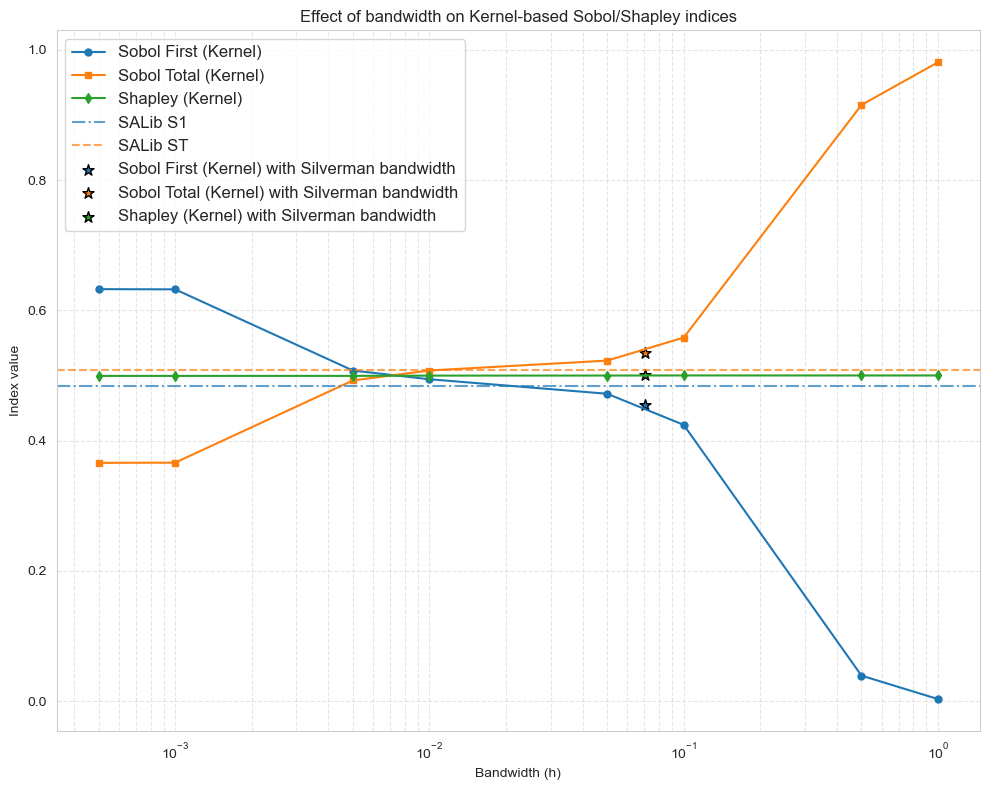

In [11]:
bandwidths = [0.0005, 0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1]

Y = Y_2

S1_list, ST_list, Shapley_list = [], [], []

for b in bandwidths:
    S1_df = sobol_first_order_kernel(param_values, Y.reshape(-1, 1), bandwidth=b)
    ST_df = sobol_total_order_kernel(param_values, Y.reshape(-1, 1), bandwidth=b)
    Shapley_df = shapley_values_kernel(param_values, Y.reshape(-1, 1), bandwidth=b)

    S1_list.append(S1_df.iloc[0, 0])
    ST_list.append(ST_df.iloc[0, 0])
    Shapley_list.append(Shapley_df.iloc[0, 0])

# SALib baseline
Si = sobol.analyze(problem, Y, calc_second_order=True, print_to_console=False)
S1_base = Si['S1'][0]
ST_base = Si['ST'][0]

# Silverman bandwidth
bw_silverman = silverman_bandwidths(param_values)[0]
S1_silver = sobol_first_order_kernel(param_values, Y.reshape(-1, 1), bandwidth=bw_silverman).iloc[0,0]
ST_silver = sobol_total_order_kernel(param_values, Y.reshape(-1, 1), bandwidth=bw_silverman).iloc[0,0]
Shapley_silver = shapley_values_kernel(param_values, Y.reshape(-1, 1), bandwidth=bw_silverman).iloc[0,0]

plt.figure(figsize=(10, 8))

# Sobol First
plt.plot(bandwidths, S1_list, 'o-', color='C0', label="Sobol First (Kernel)", markersize=5)

# Sobol Total
plt.plot(bandwidths, ST_list, 's-', color='C1', label="Sobol Total (Kernel)", markersize=5)

# Shapley
plt.plot(bandwidths, Shapley_list, 'd-', color='C2', label="Shapley (Kernel)", markersize=5)

plt.axhline(S1_base, color='C0', linestyle='-.', alpha=0.7, label="SALib S1")
plt.axhline(ST_base, color='C1', linestyle='--', alpha=0.7, label="SALib ST")

plt.scatter(bw_silverman, S1_silver, marker='*', color='C0', s=70, edgecolors='black', label="Sobol First (Kernel) with Silverman bandwidth")
plt.scatter(bw_silverman, ST_silver, marker='*', color='C1', s=70, edgecolors='black', label="Sobol Total (Kernel) with Silverman bandwidth")
plt.scatter(bw_silverman, Shapley_silver, marker='*', color='C2', s=70, edgecolors='black', label="Shapley (Kernel) with Silverman bandwidth")


plt.xscale("log")
plt.xlabel("Bandwidth (h)")
plt.ylabel("Index value")
plt.title("Effect of bandwidth on Kernel-based Sobol/Shapley indices")
plt.legend(fontsize=12)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
decimal = 3
print(sobol_first_order_discrete(param_values, Y.reshape(-1, 1), decimals=decimal))
print(sobol_total_order_discrete(param_values, Y.reshape(-1, 1), decimals=decimal))
print(shapley_values_discrete(param_values, Y.reshape(-1, 1), decimals=decimal))

In [12]:
n_bin = 10
print(sobol_first_order_continuous(param_values, Y.reshape(-1, 1), n_bins=n_bin))
print(sobol_total_order_continuous(param_values, Y.reshape(-1, 1), n_bins=n_bin))

          f1
x1  0.484539
x2  0.485662
          f1
x1  0.517052
x2  0.518183


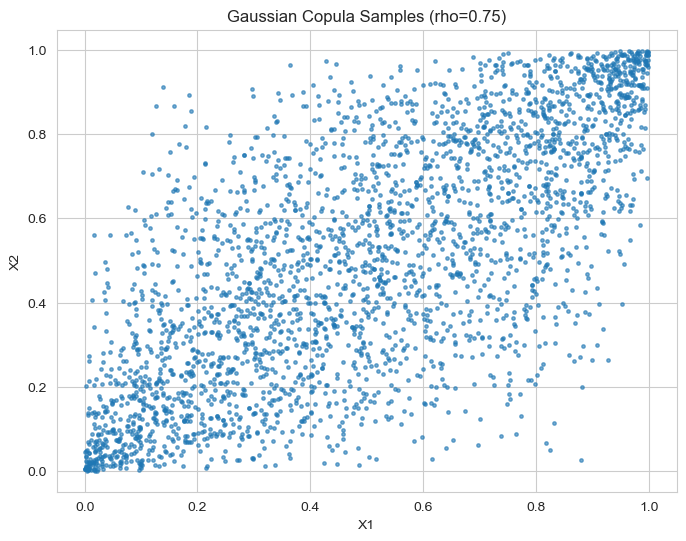

In [13]:
def gaussian_copula_uniform(n, rho, seed=None):
    rng = np.random.default_rng(seed)
    mean = np.zeros(2)
    cov = np.array([[1.0, rho],
                    [rho, 1.0]])
    Z = rng.multivariate_normal(mean, cov, size=n)  # (n, 2)
    U = norm.cdf(Z)
    return U

rho = 0.75
X = gaussian_copula_uniform(3000, rho, seed=42)
Y = model_2(X)

plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], s=6, alpha=0.6)
plt.xlabel("X1")
plt.ylabel("X2")
plt.title(f"Gaussian Copula Samples (rho={rho})")
plt.show()

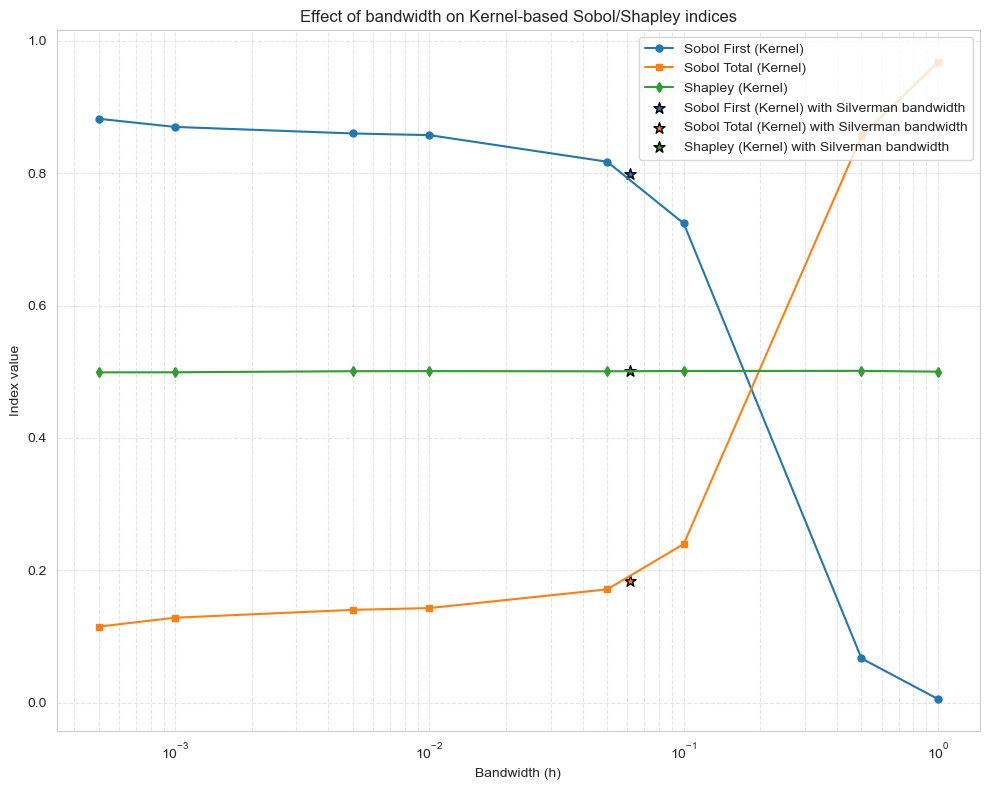

In [15]:
bandwidths = [0.0005, 0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1]

S1_list, ST_list, Shapley_list = [], [], []

for b in bandwidths:
    S1_df = sobol_first_order_kernel(X, Y.reshape(-1, 1), bandwidth=b)
    ST_df = sobol_total_order_kernel(X, Y.reshape(-1, 1), bandwidth=b)
    Shapley_df = shapley_values_kernel(X, Y.reshape(-1, 1), bandwidth=b)

    S1_list.append(S1_df.iloc[0, 0])
    ST_list.append(ST_df.iloc[0, 0])
    Shapley_list.append(Shapley_df.iloc[0, 0])

# Silverman bandwidth
bw_silverman = silverman_bandwidths(X)[0]
S1_silver = sobol_first_order_kernel(X, Y.reshape(-1, 1), bandwidth=bw_silverman).iloc[0,0]
ST_silver = sobol_total_order_kernel(X, Y.reshape(-1, 1), bandwidth=bw_silverman).iloc[0,0]
Shapley_silver = shapley_values_kernel(X, Y.reshape(-1, 1), bandwidth=bw_silverman).iloc[0,0]

plt.figure(figsize=(10, 8))

# Sobol First
plt.plot(bandwidths, S1_list, 'o-', color='C0', label="Sobol First (Kernel)", markersize=5)

# Sobol Total
plt.plot(bandwidths, ST_list, 's-', color='C1', label="Sobol Total (Kernel)", markersize=5)

# Shapley
plt.plot(bandwidths, Shapley_list, 'd-', color='C2', label="Shapley (Kernel)", markersize=5)

plt.scatter(bw_silverman, S1_silver, marker='*', color='C0', s=70, edgecolors='black', label="Sobol First (Kernel) with Silverman bandwidth")
plt.scatter(bw_silverman, ST_silver, marker='*', color='C1', s=70, edgecolors='black', label="Sobol Total (Kernel) with Silverman bandwidth")
plt.scatter(bw_silverman, Shapley_silver, marker='*', color='C2', s=70, edgecolors='black', label="Shapley (Kernel) with Silverman bandwidth")


plt.xscale("log")
plt.xlabel("Bandwidth (h)")
plt.ylabel("Index value")
plt.title("Effect of bandwidth on Kernel-based Sobol/Shapley indices")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [17]:
# Example 5

def gen_xy_phi_negative(n=10000, seed=123):
    rng = np.random.default_rng(seed)
    Sigma = np.array([
        [1.0, 0.0, 0.5],
        [0.0, 1.0, 0.5],
        [0.5, 0.5, 1.0]
    ])
    a = np.array([2.0, 2.0, -1.0])
    Z = rng.multivariate_normal(mean=np.zeros(3), cov=Sigma, size=n)
    Y = Z @ a
    X = Z
    return X, Y, Sigma, a

X, Y, Sigma, a = gen_xy_phi_negative(n=5000, seed=123)

b = silverman_bandwidths(X) * 0.6
print(sobol_first_order_kernel(X, Y.reshape(-1, 1), bandwidth=b))
print(sobol_total_order_kernel(X, Y.reshape(-1, 1), bandwidth=b))
print(shapley_values_kernel(X, Y.reshape(-1, 1), bandwidth=b))


          f1
x1  0.436470
x2  0.447584
x3  0.191905
          f1
x1  0.513510
x2  0.524332
x3  0.106363
          f1
x1  0.435114
x2  0.448816
x3  0.116069


In [18]:
from itertools import combinations
from math import factorial

def total_variance(Sigma, a):
    return float(a.T @ Sigma @ a)

def cov_vector(Sigma, a):
    return Sigma @ a

def first_order_sobol(Sigma, a):

    varY = total_variance(Sigma, a)
    c = cov_vector(Sigma, a)
    diag = np.diag(Sigma)
    S = (c**2) / (varY * diag)
    return S

def conditional_var_one(Sigma, i):
    d = Sigma.shape[0]
    idx_all = np.arange(d)
    idx_rest = np.delete(idx_all, i)
    S_ii = Sigma[i, i]
    S_iR = Sigma[i, idx_rest]
    S_Ri = Sigma[idx_rest, i]
    S_RR = Sigma[idx_rest][:, idx_rest]
    x = np.linalg.solve(S_RR, S_Ri)
    return float(S_ii - S_iR @ x)

def total_effect_sobol(Sigma, a):
    varY = total_variance(Sigma, a)
    d = len(a)
    ST = np.empty(d, dtype=float)
    for i in range(d):
        ST[i] = (a[i]**2) * conditional_var_one(Sigma, i) / varY
    return ST

def V_of_S(Sigma, a, S):
    if len(S) == 0:
        return 0.0
    d = Sigma.shape[0]
    if len(S) == d:
        return total_variance(Sigma, a)
    S = np.array(sorted(S), dtype=int)
    Sig_SS = Sigma[np.ix_(S, S)]
    Sig_allS = Sigma[:, S]
    M = np.linalg.solve(Sig_SS, Sig_allS.T)
    A = Sig_allS @ M
    return float(a.T @ A @ a)

def shapley_effects(Sigma, a):
    d = len(a)
    varY = total_variance(Sigma, a)
    fact = [factorial(k) for k in range(d+1)]
    denom = fact[d]
    phi = np.zeros(d, dtype=float)

    idx_all = tuple(range(d))
    from functools import lru_cache
    @lru_cache(maxsize=None)
    def V_cached(S_tuple):
        return V_of_S(Sigma, a, list(S_tuple))

    for i in range(d):
        others = [j for j in idx_all if j != i]
        for k in range(0, d):
            for S in combinations(others, k):
                w = fact[k] * fact[d - k - 1] / denom
                V_S     = V_cached(S)
                V_S_i   = V_cached(tuple(sorted(S + (i,))))
                phi[i] += w * (V_S_i - V_S)
    return phi / varY

In [19]:
S_first = first_order_sobol(Sigma, a)
S_total = total_effect_sobol(Sigma, a)
phi = shapley_effects(Sigma, a)
S_first, S_total, phi

(array([0.45, 0.45, 0.2 ]),
 array([0.53333333, 0.53333333, 0.1       ]),
 array([0.44722222, 0.44722222, 0.10555556]))

In [21]:
bandwidths = [0.0005, 0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1]

S1_list, ST_list, Shapley_list = [], [], []

for b in bandwidths:
    S1_df = sobol_first_order_kernel(X, Y.reshape(-1, 1), bandwidth=b)
    ST_df = sobol_total_order_kernel(X, Y.reshape(-1, 1), bandwidth=b)
    Shapley_df = shapley_values_kernel(X, Y.reshape(-1, 1), bandwidth=b)

    S1_list.append(S1_df.iloc[0, 0])
    ST_list.append(ST_df.iloc[0, 0])
    Shapley_list.append(Shapley_df.iloc[0, 0])

# Silverman bandwidth
bw_silverman = silverman_bandwidths(X)[0]
S1_silver = sobol_first_order_kernel(X, Y.reshape(-1, 1), bandwidth=bw_silverman).iloc[0,0]
ST_silver = sobol_total_order_kernel(X, Y.reshape(-1, 1), bandwidth=bw_silverman).iloc[0,0]
Shapley_silver = shapley_values_kernel(X, Y.reshape(-1, 1), bandwidth=bw_silverman).iloc[0,0]


KeyboardInterrupt: 

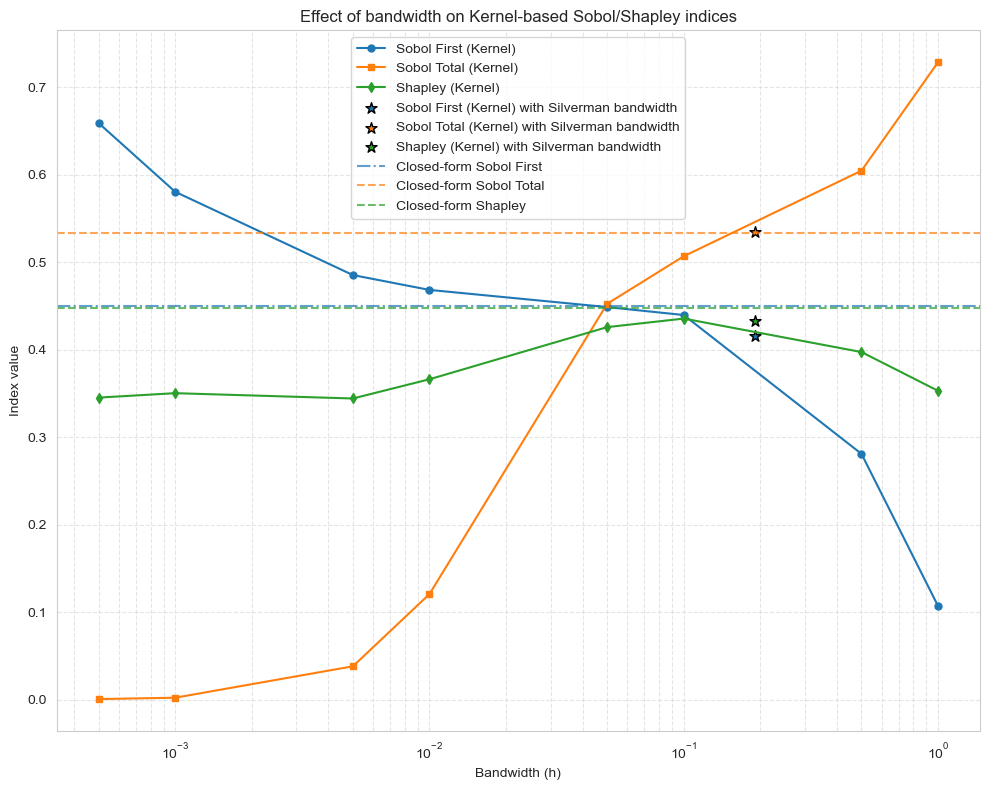

In [202]:

plt.figure(figsize=(10, 8))

# Sobol First
plt.plot(bandwidths, S1_list, 'o-', color='C0', label="Sobol First (Kernel)", markersize=5)

# Sobol Total
plt.plot(bandwidths, ST_list, 's-', color='C1', label="Sobol Total (Kernel)", markersize=5)

# Shapley
plt.plot(bandwidths, Shapley_list, 'd-', color='C2', label="Shapley (Kernel)", markersize=5)

plt.scatter(bw_silverman, S1_silver, marker='*', color='C0', s=70, edgecolors='black', label="Sobol First (Kernel) with Silverman bandwidth")
plt.scatter(bw_silverman, ST_silver, marker='*', color='C1', s=70, edgecolors='black', label="Sobol Total (Kernel) with Silverman bandwidth")
plt.scatter(bw_silverman, Shapley_silver, marker='*', color='C2', s=70, edgecolors='black', label="Shapley (Kernel) with Silverman bandwidth")

plt.axhline(S_first[0], color='C0', linestyle='-.', alpha=0.7, label="Closed-form Sobol First")
plt.axhline(S_total[0], color='C1', linestyle='--', alpha=0.7, label="Closed-form Sobol Total")
plt.axhline(phi[0], color='C2', linestyle='--', alpha=0.7, label="Closed-form Shapley")

plt.xscale("log")
plt.xlabel("Bandwidth (h)")
plt.ylabel("Index value")
plt.title("Effect of bandwidth on Kernel-based Sobol/Shapley indices")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
def make_problem(D):
    return {
        'num_vars': D,
        'names': [f'X{i+1}' for i in range(D)],
        'bounds': [[0.0, 1.0]] * D
    }


def model(X):
    return X.sum(axis=1)


def run(D, N = 1024):
    X = sobol.sample(make_problem(D), N, calc_second_order=False)
    Y = model(X)
    return X, Y


In [ ]:
import time
import pandas as pd
from tqdm.notebook  import tqdm

def timed_call(func, *args, **kwargs):
    t0 = time.perf_counter()
    out = func(*args, **kwargs)
    t1 = time.perf_counter()
    return out, t1 - t0

REPS = 30
Ds = [2, 3, 5, 6, 8, 10]

rows = []

for d in tqdm(Ds, desc="Dims"):
    for rep in tqdm(range(REPS), desc="Reps"):
        X, Y = run(d)
        Y = Y.reshape(-1, 1)

        row = {"D": d, "rep": rep}

        # Sobol first-order (discrete)
        _, row["time_S1_disc"] = timed_call(sobol_first_order_discrete, X, Y, decimals=decimal)

        # Bandwidth
        b, row["time_bandwidth"] = timed_call(silverman_bandwidths, X)

        # Sobol first-order (kernel)
        _, row["time_S1_kernel"] = timed_call(sobol_first_order_kernel, X, Y, bandwidth=b)

        # Sobol total-order (kernel)
        _, row["time_ST_kernel"] = timed_call(sobol_total_order_kernel, X, Y, bandwidth=b)

        # Shapley kernel
        _, row["time_Shapley_kernel"] = timed_call(shapley_values_kernel, X, Y, bandwidth=b)

        rows.append(row)

df_times = pd.DataFrame(rows)



In [ ]:
df_times.to_csv("../results/gsa/gsa_times.csv", index=False)

C:\Users\chiarul\AppData\Local\Temp\ipykernel_53104\709417994.py:43: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0.

  sns.pointplot(


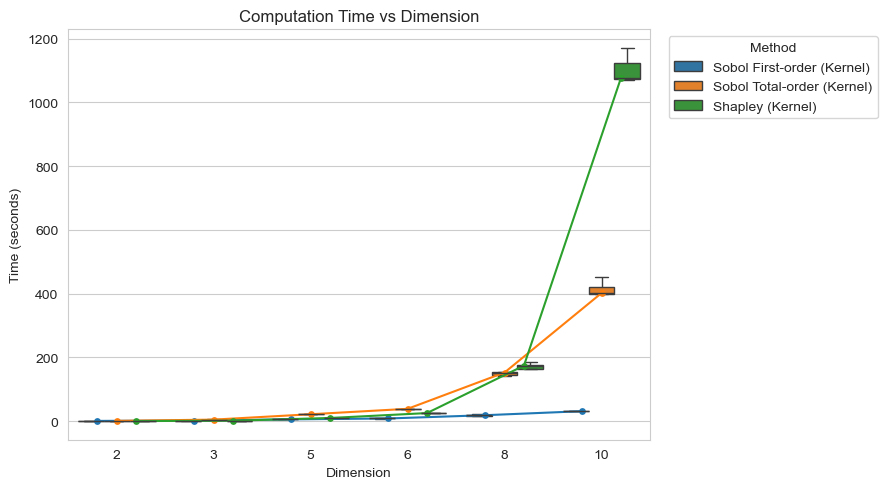

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import LogLocator, LogFormatter

df_times = pd.read_csv("../results/gsa/gsa_times.csv")

# --- Keep only these three timing columns
method_cols = ["time_S1_kernel", "time_ST_kernel", "time_Shapley_kernel"]
label_map = {
    "time_S1_kernel": r"Sobol First-order (Kernel)",
    "time_ST_kernel": r"Sobol Total-order (Kernel)",
    "time_Shapley_kernel": "Shapley (Kernel)"
}

# ---- Prepare long-form data
df_long = df_times.melt(id_vars=["D", "rep"], value_vars=method_cols,
                        var_name="Method", value_name="Time")
df_long["Method"] = df_long["Method"].map(label_map)

# Ensure consistent ordering
method_order = [label_map[k] for k in method_cols]
df_long["Method"] = pd.Categorical(df_long["Method"],
                                   categories=method_order, ordered=True)

# Make x categorical so pointplot aligns with the dodged boxes
df_long["D"] = df_long["D"].astype(str)
order_D = sorted(df_long["D"].unique(), key=lambda s: int(s))

# Replace zeros to avoid log-scale issues (if any)
df_long["Time"] = df_long["Time"].replace(0, 1e-6)

# ---- Plot
sns.set_style("whitegrid")
plt.figure(figsize=(9, 5))
ax = sns.boxplot(
    data=df_long, x="D", y="Time", hue="Method",
    order=order_D, showfliers=False, width=0.8
)

# Overlay median lines
sns.pointplot(
    data=df_long, x="D", y="Time", hue="Method",
    order=order_D, dodge=0.4, join=True, markers="o",
    estimator=np.median, errorbar=None, linewidth=1.5, legend=False
)

# Log y-axis with explicit base = 10
# ax.set_yscale("log", base=10)

# Ticks/format for log10
# ax.yaxis.set_major_locator(LogLocator(base=10))
# ax.yaxis.set_major_formatter(LogFormatter(base=10))

# Label explicitly shows base-10
ax.set_ylabel(r"Time (seconds)")

plt.title("Computation Time vs Dimension")
plt.xlabel("Dimension")
plt.legend(title="Method", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

plt.show()


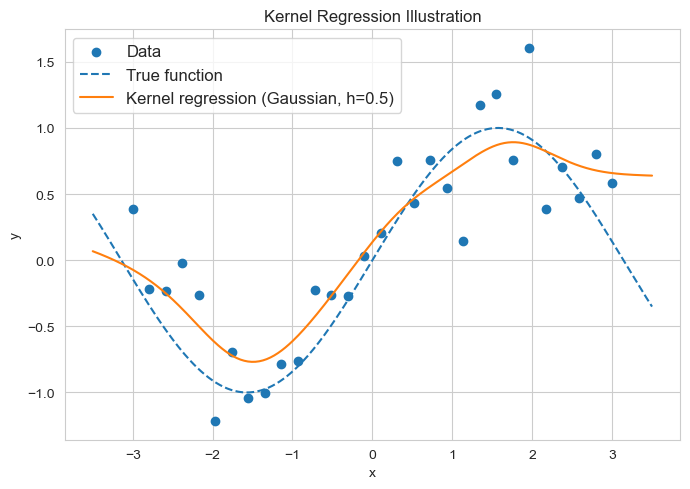

In [25]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)
X = np.linspace(-3, 3, 30)           # (n,)
y = np.sin(X) + 0.3 * np.random.randn(X.size)

X_plot = np.linspace(-3.5, 3.5, 300)  # (m,)

def nw_predict(x_grid, X, y, h=0.5):
    diffs = (x_grid[None, :] - X[:, None]) / h
    W = np.exp(-0.5 * diffs**2)              # (n, m)
    W_sum = W.sum(axis=0, keepdims=True)     # (1, m)
    W = W / (W_sum + 1e-12)
    y_hat = (W * y[:, None]).sum(axis=0)     # (m,)
    return y_hat

y_est = nw_predict(X_plot, X, y, h=0.5)

plt.figure(figsize=(7, 5))
plt.scatter(X, y, label="Data")
plt.plot(X_plot, np.sin(X_plot), linestyle="--", label="True function")
plt.plot(X_plot, y_est, label="Kernel regression (Gaussian, h=0.5)")
plt.title("Kernel Regression Illustration")
plt.xlabel("x"); plt.ylabel("y")
plt.legend(fontsize=12, loc="upper left")
plt.tight_layout()
plt.show()


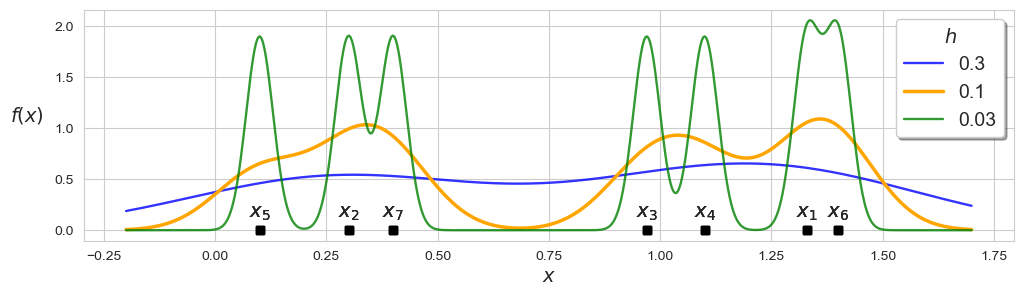

In [27]:
# the Kernel function
def K(x):
    return np.exp(-x**2/2)/np.sqrt(2*np.pi)

# dummy dataset
dataset = np.array([1.33, 0.3, 0.97, 1.1, 0.1, 1.4, 0.4])

# x-value range for plotting KDEs
x_range = np.linspace(dataset.min()-0.3, dataset.max()+0.3, num=600)

# bandwith values for experimentation
H = [0.3, 0.1, 0.03]
n_samples = dataset.size

# line properties for different bandwith values
color_list = ['blue', 'orange', 'green']
alpha_list = [0.8, 1, 0.8]
width_list = [1.7,2.5,1.7]

plt.figure(figsize=(12, 3))
# iterate over bandwith values
for h, color, alpha, width in zip(H, color_list, alpha_list, width_list):
    total_sum = 0
    # iterate over datapoints
    for i, xi in enumerate(dataset):
        total_sum += K((x_range - xi) / h)
        plt.annotate(r'$x_{}$'.format(i+1),
                     xy=[xi, 0.13],
                     horizontalalignment='center',
                     fontsize=14,
                    )
    y_range = total_sum/(h*n_samples)
    plt.plot(x_range, y_range,
             color=color, alpha=alpha, linewidth=width,
             label=f'{h}')

    plt.plot(dataset, np.zeros_like(dataset) , 's',
             markersize=6, color='black')

plt.xlabel('$x$', fontsize=14)
plt.ylabel('$f(x)$', fontsize=14, rotation='horizontal', labelpad=20)
plt.legend(fontsize=14, shadow=True, title='$h$', title_fontsize=14)
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---- anchors from your example ----
a = np.array([0.0, 0.0])   # for f1(x)=||x-a||^2
b = np.array([2.0, 1.0])   # for f2(x)=||x-b||^2
d = b - a                  # direction vector of the Pareto line segment

# ---- decision space: U(0,1)^2 ----
rng = np.random.default_rng(42)
N = 8000
X1 = rng.uniform(0.0, 1.0, size=N)
X2 = rng.uniform(0.0, 1.0, size=N)

# ---- clip the segment [a,b] to the unit square [0,1]^2 ----
# Param: p(t) = a + t*d, t in [0,1]
t_lo, t_hi = 0.0, 1.0
for i in range(2):
    if d[i] > 0:
        t_lo = max(t_lo, (0.0 - a[i]) / d[i])
        t_hi = min(t_hi, (1.0 - a[i]) / d[i])
    elif d[i] < 0:
        t_lo = max(t_lo, (1.0 - a[i]) / d[i])
        t_hi = min(t_hi, (0.0 - a[i]) / d[i])
    else:
        # segment is parallel to this axis; must lie inside the band
        if not (0.0 <= a[i] <= 1.0):
            t_lo, t_hi = 1.0, 0.0  # no intersection
            break

t_lo = max(0.0, t_lo); t_hi = min(1.0, t_hi)
has_intersection = t_lo <= t_hi

# endpoints of the clipped Pareto set inside the square
if has_intersection:
    p0 = a + t_lo * d
    p1 = a + t_hi * d
else:
    p0 = p1 = None

# ---- plot: square figure, uniform decision samples, highlighted Pareto set ----
plt.figure(figsize=(8, 6))

# soft scatter background
plt.scatter(X1, X2, s=8, alpha=0.25, c='#6c6c6c', edgecolors='none', rasterized=True, zorder=1)

# highlight Pareto set (clipped segment)
# if has_intersection:
    # plt.plot([p0[0], p1[0]], [p0[1], p1[1]], lw=3, color='#ff6a00', zorder=3, label='Pareto set')

ax = plt.gca()
ax.set_aspect('equal', 'box')     # keep the plot square
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.grid(True, alpha=0.2, linewidth=0.8)

plt.xlabel(r'$x_1$'); plt.ylabel(r'$x_2$')
# plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


In [ ]:
from matplotlib.collections import LineCollection
from math import gamma

# ---------------- Preference → probability on the Pareto set ----------------
def beta_pdf(t, a_param, b_param):
    B = gamma(a_param) * gamma(b_param) / gamma(a_param + b_param)
    return (t**(a_param-1)) * ((1-t)**(b_param-1)) / B

alpha1, alpha2 = 3.0, 1.0
Nseg = 1000

# t grid on the clipped segment
t = np.linspace(t_lo, t_hi, Nseg)
pdf = beta_pdf(t, a_param=alpha2, b_param=alpha1)
# normalize PDF on [t_lo, t_hi]
pdf /= np.trapz(pdf, t) + 1e-12

# probability mass per small segment (trapezoid rule)
dt = t[1] - t[0]
seg_prob = 0.5 * (pdf[:-1] + pdf[1:]) * dt   # sums to ~1
# for coloring, associate each segment with its probability
pts = a[None, :] + t[:, None] * d[None, :]
segments = np.stack([pts[:-1], pts[1:]], axis=1)

# ---------------- Plot (same style, but colored by probability) ----------------
plt.figure(figsize=(8, 6))

# soft scatter background of decision space
plt.scatter(
    X1, X2,
    s=8, marker='o', alpha=0.25,
    c='#6c6c6c', edgecolors='none', rasterized=True, zorder=1
)

ax = plt.gca()

if has_intersection:
    lc = LineCollection(
        segments,
        cmap='magma',
        norm=plt.Normalize(vmin=0.0, vmax=seg_prob.max()),
        zorder=3
    )
    lc.set_array(seg_prob)     # color by probability (per segment)
    lc.set_linewidth(6.0)
    ax.add_collection(lc)

    # probability colorbar
    cbar = plt.colorbar(lc, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label('Probability')

# aesthetics
ax.set_aspect('equal', 'box')
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.grid(True, alpha=0.2, linewidth=0.8)

plt.xlabel(r'$x_1$'); plt.ylabel(r'$x_2$')
plt.tight_layout()
plt.show()



In [ ]:
# --- plot ---
plt.figure(figsize=(8, 6))

# feasible region scatter
plt.scatter(X1, X2, s=8, alpha=0.25, c='#6c6c6c',
            edgecolors='none', rasterized=True, zorder=1, label='feasible samples')

# draw unit square boundary
plt.plot([0,1,1,0,0], [0,0,1,1,0], color='#444', lw=1.2, alpha=0.8, zorder=2)

# full anchor-to-anchor segment (for context)
plt.plot([a[0], b[0]], [a[1], b[1]], ls='--', lw=2, color='#9aa0a6', zorder=2)

# clipped segment inside [0,1]^2 = Pareto set within feasible region
if has_intersection:
    plt.plot([p0[0], p1[0]], [p0[1], p1[1]], lw=3, color='#ff6a00', zorder=3, label='Pareto set')

# anchor points and labels
plt.scatter([a[0], b[0]], [a[1], b[1]], s=48, c='black', zorder=4)
plt.annotate('a', a + np.array([0.04, 0.1]), fontsize=14)
plt.annotate('b', b + np.array([0.04, 0.04]), fontsize=14)

ax = plt.gca()
ax.set_aspect('equal', 'box')
ax.set_xlim(-0.05, 2.05); ax.set_ylim(-0.05, 1.05)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.grid(True, alpha=0.2, linewidth=0.8)

plt.xlabel(r'$x_1$'); plt.ylabel(r'$x_2$')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from SALib.sample import saltelli
from SALib.analyze import sobol
from scipy.stats import gamma as sp_gamma


clip_to_unit = True

def model_f12(U):
    eps = 1e-12
    u1 = np.clip(U[:, 0], eps, 1 - eps)
    u2 = np.clip(U[:, 1], eps, 1 - eps)

    G1 = sp_gamma.ppf(u1, a=alpha1, scale=1.0)
    G2 = sp_gamma.ppf(u2, a=alpha2, scale=1.0)
    s = G1 + G2
    beta1 = G1 / s
    beta2 = G2 / s

    X = beta1[:, None] * a[None, :] + beta2[:, None] * b[None, :]
    if clip_to_unit:
        X = np.clip(X, [0.0, 0.0], [1.0, 1.0])

    f1 = np.sum((X - a)**2, axis=1)
    f2 = np.sum((X - b)**2, axis=1)
    return np.column_stack([f1, f2])

problem = {
    "num_vars": 2,
    "names": ["u1", "u2"],
    "bounds": [[0.0, 1.0], [0.0, 1.0]],
}

N_base = 20000
param_values = saltelli.sample(problem, N_base, calc_second_order=False)
Y = model_f12(param_values)  # shape (Nsamples, 2) = [f1, f2]

obj_names = [r"$f_1(x^*)$", r"$f_2(x^*)$"]
var_names = [r"$x_1$", r"$x_2$"]

first = []
total = []
for j in range(Y.shape[1]):
    Si = sobol.analyze(problem, Y[:, j], calc_second_order=False, print_to_console=False)
    first.append(Si["S1"])
    total.append(Si["ST"])
first = np.array(first).T
total = np.array(total).T

n_obj = len(obj_names)

fig, axes = plt.subplots(1, n_obj, figsize=(4 * n_obj, 5), sharey=True)
if n_obj == 1:
    axes = [axes]

x = np.arange(len(var_names))
width = 0.35

for j, ax in enumerate(axes):
    ax.bar(x - width/2, first[:, j], width, label="First-order")
    ax.bar(x + width/2, total[:, j], width, label="Total-order")
    ax.set_title(f"Sensitivity for {obj_names[j]}")
    ax.set_xticks(x)
    ax.set_xticklabels(var_names)
    ax.set_ylim(0, 1.1)
    ax.grid(True, linestyle="--", alpha=0.3)

axes[-1].legend()
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


In [10]:
import numpy as np
from scipy.optimize import root_scalar

def f(alpha):  # derivative = 0
    return 2*np.log(1/alpha) + 2*alpha - 3

sol = root_scalar(f, bracket=[1e-3, 1], method='brentq')
alpha_star = sol.root

def P(alpha):
    return 2*alpha*np.log(1/alpha) - alpha*(1-alpha)

print("alpha* =", alpha_star)
print("P_max  =", P(alpha_star))


alpha* = 0.301709562684336
P_max  = 0.5123904651534987


In [38]:
# X = np.array([[4.5, 6, 1, 1, 15, 34],
#               [5, 6, 1, 1, 15, 34],
#               [6, 6, 1, 1, 15, 34],
#               [4.5, 6, 1, 1, 6, 34],
#               [6, 6, 1, 1, 6, 34],
#               [4.5, 6, 1, 1, 4.5, 132],
#               [4.5, 6, 1, 1, 4.5, 34],
#               [4.5, 6, 1, 1, 0, 132]])

X = np.array([[4.5, 6, 1, 1, 15, 34],
              [4.5, 6, 1, 1, 15, 34],
              [4.5, 6, 1, 1, 15, 34],
              [4.5, 6, 1, 1, 15, 34],
              [4.5, 6, 1, 1, 15, 34],
              [4.5, 6, 1, 1, 6, 34],
              [4.5, 6, 1, 1, 6, 34],
              [4.5, 6, 1, 1, 4.5, 132],
              [4.5, 6, 1, 1, 4.5, 34],
              [4.5, 6, 1, 1, 0, 132]])

In [39]:
f1 = np.maximum((X[:, 0] - X[:, 4]), 0)
f2 = f1 + np.maximum((X[:, 1] - X[:, 4]), 0) + X[:, 5]

In [40]:
gsa.sobol_first_order_kernel(X, f1.reshape(-1, 1))

,g1
t1,0.000000
t2,0.000000
t3,0.000000
t4,0.000000
t5,1.000000
t6,0.444444
